### Bài thực hành số 4: Phát hiện giao dịch gian lận

Giới thiệu về Dataset:
Bộ dữ liệu IBM Transactions for Anti-Money Laundering (AML) do IBM Research phát triển nhằm giải quyết bài toán thiếu hụt dữ liệu chuẩn (benchmark) trong nghiên cứu phòng chống rửa tiền. Do rào cản bảo mật ngân hàng và quy định quyền riêng tư (GDPR), dữ liệu giao dịch tài chính thật không thể công khai. IBM đã sử dụng các mô phỏng đa tác tử (Multi-Agent Simulation) để tạo ra tập dữ liệu tổng hợp (Synthetic Data) phản ánh chính xác hành vi giao dịch ngân hàng ngoài đời thực.

Tệp HI-Small_trans.csv là phiên bản quy mô nhỏ thuộc dòng tệp HI (High-Involvement - Mức độ phức tạp mạng lưới cao)
+ Quy mô: Khoảng 5 triệu dòng giao dịch (dung lượng chưa nén khoảng 500 MB – 600 MB), vừa đủ gọn để chạy thực hành trên các máy trạm cá nhân hoặc cụm Spark nhỏ.
+ Cấu trúc ma trận mạng: Hàng trăm nghìn tài khoản (Accounts) tạo thành một Đồ thị Hướng Đa cạnh (Directed Multigraph), trong đó 2 tài khoản có thể thực hiện nhiều giao dịch ở các thời điểm khác nhau.

Cấu trúc dữ liệu:
Timestamp: Thời gian thực hiện giao dịch (yyyy/MM/dd HH:mm), dùng để xác định tính tuần tự thời gian giữa các nấc rửa tiền (Temporal Ordering).

From Bank: Mã định danh ngân hàng gửi.

Account2: Mã định danh tài khoản nguồn (src), đóng vai trò nút nguồn trên đồ thị.

To Bank: Mã định danh ngân hàng nhận.

Account4: Mã định danh tài khoản đích (dst), đóng vai trò nút đích trên đồ thị.

Amount Received: Số tiền tài khoản nhận thực tế thu về (sau khi quy đổi hoặc trừ phí).

Receiving Currency: Loại tiền tệ tài khoản nhận thu về.

Amount Paid: Số tiền tài khoản gửi chuyển đi, đặc trưng quan trọng để phát hiện hành vi chia nhỏ số tiền (Structuring).

Payment Currency: Loại tiền tệ dùng khi chuyển đi.

Payment Format: Phương thức thanh toán (ACH, Wire, Cheque, Credit Card, Cash), giúp nhận diện kênh giao dịch có rủi ro cao.

Is Laundering: Nhãn thực tế (Target Label) với 0 là giao dịch hợp lệ và 1 là giao dịch rửa tiền.

+ File dữ liệu thực hành: https://www.kaggle.com/datasets/ealtman2019/ibm-transactions-for-anti-money-laundering-aml?resource=download&select=HI-Small_Trans.csv

### Kết quả lần chạy đã lưu — mẫu 2% dữ liệu IBM gốc
Đã thực thi toàn bộ notebook trên **101.813** giao dịch hợp lệ, gồm **91** nhãn rửa tiền.
Tập test có **20.340** giao dịch, **30** nhãn dương. Hai mô hình cùng chọn ngưỡng **0,7** bằng validation.
Thêm đặc trưng đồ thị lịch sử làm accuracy tăng **97,6647% → 98,0728%** và F1 tăng **0,059406 → 0,062201**,
nhưng PR-AUC giảm **0,029607 → 0,026411**, recall giảm **0,5000 → 0,4333**.
Vì vậy chưa thể kết luận mô hình đồ thị tốt hơn toàn diện. **Chưa chạy toàn bộ tệp IBM**;
lấy mẫu cạnh có thể làm đứt các chuỗi/mạng giao dịch, và số nhãn test nhỏ làm kết quả nhạy với từng giao dịch.
Đặt `AML_FRACTION=1.0` để chạy toàn bộ trên máy có tài nguyên phù hợp; mặc định của code là 1.0.

## Lời giải — 4 bài tập
**Dữ liệu:** [IBM AML, phiên bản Kaggle 8, HI-Small_Trans.csv](https://www.kaggle.com/datasets/ealtman2019/ibm-transactions-for-anti-money-laundering-aml?select=HI-Small_Trans.csv).
**Môi trường:** Python 3.12, Java 21, Spark 4.0.2, GraphFrames 0.12.3; xem `requirements.txt`.
Notebook mặc định đọc toàn bộ tệp; `AML_FRACTION=0.02` là chế độ kiểm tra trên mẫu 2%, có ghi rõ phạm vi trong output.
Lấy mẫu cạnh làm mất cấu trúc mạng nên kết quả trên mẫu **không đại diện** chất lượng phát hiện trên toàn đồ thị.

### Giả định
- Một nút là **cặp (ngân hàng, tài khoản)**. Dùng JSON struct để tránh va chạm khi nối chuỗi.
- Fan-in/mule/layering là dấu hiệu để điều tra, không là kết luận một giao dịch đã rửa tiền.
- Chỉ so sánh số tiền có cùng tiền tệ; không cộng USD với EUR hoặc tiền tệ khác.
- Ngưỡng số tiền/thời gian dưới đây là tham số minh họa của bài, không phải ngưỡng pháp lý.
- Motif trên toàn dữ liệu phục vụ mô tả. Phần dự đoán dùng một snapshot quá khứ riêng để tránh nhìn trước tương lai.

Chuẩn bị môi trường Spark

In [1]:
import os, csv
from pathlib import Path
ROOT=Path.cwd().resolve()
if ROOT.name=='loi_giai': ROOT=ROOT.parent
os.chdir(ROOT)
import sys
os.environ['PYSPARK_PYTHON'] = sys.executable
os.environ.setdefault('SPARK_LOCAL_IP','127.0.0.1')
from pyspark.sql import SparkSession, functions as F
from graphframes import GraphFrame
spark=(SparkSession.builder.master('local[2]').appName('IBM_AML_Solutions')
    .config('spark.driver.memory','2g').config('spark.sql.shuffle.partitions','8')
    .config('spark.sql.session.timeZone','UTC').config('spark.ui.enabled','false').config('spark.ui.showConsoleProgress','false')
    .config('spark.jars.packages','io.graphframes:graphframes-spark4_2.13:0.12.3')
    .getOrCreate())
spark.sparkContext.setLogLevel('ERROR')
spark.sparkContext.setCheckpointDir(str(ROOT/'loi_giai/checkpoints'))
AML_FRACTION=float(os.environ.get('AML_FRACTION','1.0'))
assert 0 < AML_FRACTION <= 1

:: loading settings :: url = jar:file:/home/kent/BaiTapMonPhanTichKhaiPhaDuLieuLon/.venv-labs/lib/python3.12/site-packages/pyspark/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml
Ivy Default Cache set to: /home/kent/.ivy2.5.2/cache
The jars for the packages stored in: /home/kent/.ivy2.5.2/jars
io.graphframes#graphframes-spark4_2.13 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-b4f52674-1b84-4f2f-b913-d68633535347;1.0
	confs: [default]
	found io.graphframes#graphframes-spark4_2.13;0.12.3 in central
	found io.graphframes#graphframes-graphx-spark4_2.13;0.12.3 in central
	found org.apache.datasketches#datasketches-java;6.2.0 in central
	found org.apache.datasketches#datasketches-memory;3.0.2 in central
:: resolution report :: resolve 99ms :: artifacts dl 3ms
	:: modules in use:
	io.graphframes#graphframes-graphx-spark4_2.13;0.12.3 from central in [default]
	io.graphframes#graphframes-spark4_2.13;0.12.3 from central in [default]
	or

26/10/27 22:03:59 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


Bước 1: Chuẩn bị dữ liệu và Khởi tạo GraphFrame
Đồ thị trong GraphFrames yêu cầu 2 DataFrame chính:
Vertices (Đỉnh): Danh sách các tài khoản ngân hàng, phải có cột định danh duy nhất là id.
Edges (Cạnh): Danh sách các giao dịch, phải có cột nguồn src (tài khoản gửi) và cột đích dst (tài khoản nhận), kèm các thuộc tính như amount, timestamp.

In [2]:
from pyspark.sql.types import StructType, StructField, StringType
DATA_PATH=Path(os.environ.get('AML_PATH',str(ROOT/'aml_data/HI-Small_Trans.csv')))
if not DATA_PATH.exists():
    raise FileNotFoundError('Tải HI-Small_Trans.csv từ nguồn ở đầu notebook và đặt vào aml_data/.')
# CSV IBM có hai cột cùng tên Account. Dùng vị trí cột để phân biệt,
# không dựa vào tên Account2/Account4 do một số bộ đọc tự sinh ra.
with DATA_PATH.open(newline='',encoding='utf-8-sig') as f:
    header=next(csv.reader(f))
expected=['Timestamp','From Bank','Account','To Bank','Account','Amount Received','Receiving Currency','Amount Paid','Payment Currency','Payment Format','Is Laundering']
normalized_header=header.copy()
if len(normalized_header)==11:
    if normalized_header[2]=='Account2': normalized_header[2]='Account'
    if normalized_header[4]=='Account4': normalized_header[4]='Account'
if normalized_header != expected:
    raise ValueError(f'Schema CSV ngoài dự kiến: {header}')
names=['timestamp_text','from_bank','from_account','to_bank','to_account','amount_received_text','receiving_currency','amount_paid_text','payment_currency','payment_format','label_text']
# Đọc theo vị trí với tên không trùng; mã tài khoản giữ kiểu chuỗi, không mất số 0 đầu.
schema=StructType([StructField(c,StringType(),True) for c in names])
df_tx_full=(spark.read.option('header',True).option('enforceSchema',True).schema(schema).csv(str(DATA_PATH)))
df_tx=df_tx_full if AML_FRACTION==1 else df_tx_full.sample(False,AML_FRACTION,seed=42)
df_tx=df_tx.dropna(subset=['from_bank','to_bank','from_account','to_account'])
edges=(df_tx.select(
    F.to_json(F.struct(F.col('from_bank').alias('bank'),F.col('from_account').alias('account'))).alias('src'),
    F.to_json(F.struct(F.col('to_bank').alias('bank'),F.col('to_account').alias('account'))).alias('dst'),
    'from_bank','to_bank',
    F.col('amount_paid_text').cast('double').alias('amount'),
    F.col('amount_received_text').cast('double').alias('amount_received'),
    F.to_timestamp('timestamp_text','yyyy/MM/dd HH:mm').alias('timestamp'),
    'receiving_currency','payment_currency','payment_format',
    F.col('label_text').cast('int').alias('is_laundering'))
    .dropna(subset=['timestamp','amount','amount_received','src','dst','payment_currency','receiving_currency','payment_format','is_laundering'])
    .filter((F.col('amount')>0)&(F.col('amount_received')>0)&F.col('is_laundering').isin(0,1))
    .filter(F.col('from_bank').isNotNull() & F.col('to_bank').isNotNull())
    .cache())
vertices=edges.select(F.col('src').alias('id')).union(edges.select(F.col('dst').alias('id'))).distinct()
g=GraphFrame(vertices,edges)
print('Nguồn:',DATA_PATH.name,'| tỷ lệ mẫu:',AML_FRACTION,'| giao dịch hợp lệ:',edges.count())
edges.groupBy('is_laundering').count().orderBy('is_laundering').show()
vertices.show(3,truncate=False)

Nguồn: HI-Small_Trans.csv | tỷ lệ mẫu: 0.02 | giao dịch hợp lệ: 101813


+-------------+------+
|is_laundering| count|
+-------------+------+
|            0|101722|
|            1|    91|
+-------------+------+



+--------------------------------------+
|id                                    |
+--------------------------------------+
|{"bank":"010","account":"8003951A0"}  |
|{"bank":"03314","account":"8003D6540"}|
|{"bank":"01292","account":"8004203B0"}|
+--------------------------------------+
only showing top 3 rows


Bước 2: Phát hiện mô hình gian lận bằng Motif Finding
Motif Finding cho phép tìm kiếm các đường đi/mô hình giao dịch bất thường bằng cú pháp khớp chuỗi (DSL).
A. Phát hiện vòng tròn giao dịch (Round-Tripping / Ring Fraud)
Tiền được chuyển lòng vòng qua các tài khoản trung gian để xóa vết (A → B → C → A):

In [3]:
cycles=(g.find('(a)-[e1]->(b); (b)-[e2]->(c); (c)-[e3]->(a)')
    .filter('a.id != b.id AND b.id != c.id AND a.id != c.id')
    .filter('e2.timestamp >= e1.timestamp AND e3.timestamp >= e2.timestamp'))
cycles.select(F.col('a.id').alias('a'),F.col('b.id').alias('b'),F.col('c.id').alias('c'),
    F.col('e1.amount').alias('amount1'),F.col('e2.amount').alias('amount2'),F.col('e3.amount').alias('amount3')).show(10,truncate=35)

+---+---+---+-------+-------+-------+
|  a|  b|  c|amount1|amount2|amount3|
+---+---+---+-------+-------+-------+
+---+---+---+-------+-------+-------+



B. Phát hiện mô hình gom tiền hoặc phân tán tiền (Scatter-Gather / Smurfing)
Một tài khoản nhận tiền từ nhiều tài khoản khác nhau trong thời gian ngắn, sau đó chuyển toàn bộ sang một tài khoản đích duy nhất:

In [ ]:
# Ghép cạnh vào/ra trước để áp dụng giới hạn 2 giờ trước khi ghép nguồn thứ hai.
# Phá đối xứng a,b bằng a.id < b.id để mỗi cặp nguồn chỉ xét một lần.
smurfing=(g.find('(a)-[e1]->(c); (c)-[e3]->(d); (b)-[e2]->(c)')
    .filter('a.id < b.id AND a.id != c.id AND b.id != c.id AND c.id != d.id AND a.id != d.id AND b.id != d.id')
    .filter('e3.timestamp >= e1.timestamp AND e3.timestamp >= e2.timestamp')
    .filter('e3.timestamp < e1.timestamp + INTERVAL 2 HOURS AND e3.timestamp < e2.timestamp + INTERVAL 2 HOURS'))
smurfing.select(F.col('a.id').alias('a'),F.col('b.id').alias('b'),F.col('c.id').alias('c'),F.col('d.id').alias('d')).show(10,truncate=35)

Bài tập 1: Dạng Fan-In (Gom tiền từ nhiều tài khoản nhỏ về 1 tài khoản tập trung)
Mô tả hành vi: Nhiều tài khoản phụ (Smurfs) thực hiện chuyển các khoản tiền nhỏ rải rác về cùng một tài khoản đích duy nhất trong một khoảng thời gian ngắn để gom thành một khoản tiền lớn.

### Lời giải bài 1 — Fan-in
Tính cửa sổ 1 giờ trượt mỗi 10 phút, nhóm theo tài khoản nhận và tiền tệ nhận.
Một cảnh báo cần ít nhất 5 người gửi **khác nhau**, mỗi khoản nhận không quá 10.000 đơn vị tiền tệ và tổng ít nhất 20.000.
Loại tự chuyển để không tính hoạt động nội bộ là nhiều nguồn. Tiền tệ được giữ trong khóa nhóm nên tổng luôn có cùng đơn vị.
Cửa sổ trượt có thể chồng lặp; cùng một giao dịch có thể xuất hiện trong nhiều cảnh báo, không cộng số cảnh báo thành số giao dịch rửa tiền.

In [5]:
MIN_SENDERS=5
SMALL_AMOUNT_MAX=10000.0
FANIN_TOTAL_MIN=20000.0
fan_in=(edges.filter((F.col('src')!=F.col('dst')) & (F.col('amount_received')<=SMALL_AMOUNT_MAX))
    .groupBy('dst','receiving_currency',F.window('timestamp','1 hour','10 minutes'))
    .agg(F.countDistinct('src').alias('distinct_senders'),F.count('*').alias('transaction_count'),
         F.sum('amount_received').alias('total_received'),
         F.min('timestamp').alias('first_at'),F.max('timestamp').alias('last_at'))
    .filter((F.col('distinct_senders')>=MIN_SENDERS)&(F.col('total_received')>=FANIN_TOTAL_MIN)))
fan_in.orderBy(F.desc('distinct_senders'),F.desc('total_received')).show(10,truncate=35)

+---+------------------+------+----------------+-----------------+--------------+--------+-------+
|dst|receiving_currency|window|distinct_senders|transaction_count|total_received|first_at|last_at|
+---+------------------+------+----------------+-----------------+--------------+--------+-------+
+---+------------------+------+----------------+-----------------+--------------+--------+-------+



Cửa sổ trượt cách nhau 10 phút có thể bỏ sót nhóm nằm sát biên; nếu cần dò chính xác mọi khoảng 1 giờ, dùng cửa sổ neo theo từng sự kiện hoặc xử lý trạng thái theo thời gian.

Bài tập 2: Dạng Tài khoản "Lừa" / Tài khoản Trung gian (Pass-through / Mule Account)
Mô tả hành vi: Tài khoản trung gian M (Money Mule) nhận tiền từ tài khoản A, sau đó nhanh chóng chuyển gần như toàn bộ số tiền đó đi cho tài khoản B trong vòng dưới 2 giờ (số tiền giữ lại trong tài khoản $M$ gần như bằng 0).

### Lời giải bài 2 — Mule / Pass-through
Tìm đường `A → M → B` qua 3 tài khoản khác nhau. M chuyển tiếp sau khi nhận, chênh lệch **nhỏ hơn 2 giờ**.
So sánh tiền M thực nhận với tiền M trả tiếp cùng loại tiền; cho phép giữ lại tối đa 5%, không cho gửi vượt khoản đã nhận.
Đây là cách ghép cặp giao dịch, chưa chứng minh số dư tài khoản M bằng 0 vì có thể có giao dịch khác.

In [6]:
mules=(g.find('(a)-[incoming]->(m); (m)-[outgoing]->(b)')
    .filter('a.id != m.id AND m.id != b.id AND a.id != b.id')
    .filter('outgoing.timestamp >= incoming.timestamp AND outgoing.timestamp < incoming.timestamp + INTERVAL 2 HOURS')
    .filter('incoming.receiving_currency = outgoing.payment_currency')
    .filter('outgoing.amount >= 0.95 * incoming.amount_received AND outgoing.amount <= incoming.amount_received'))
mule_result=mules.select(
    F.col('a.id').alias('source'),F.col('m.id').alias('mule'),F.col('b.id').alias('destination'),
    F.col('incoming.timestamp').alias('received_at'),F.col('outgoing.timestamp').alias('sent_at'),
    F.col('incoming.receiving_currency').alias('currency'),
    F.col('incoming.amount_received').alias('received'),F.col('outgoing.amount').alias('sent'),
    (F.col('incoming.amount_received')-F.col('outgoing.amount')).alias('retained'),
    ((F.col('outgoing.timestamp').cast('long')-F.col('incoming.timestamp').cast('long'))/60).alias('delay_minutes'))
mule_result.show(10,truncate=35)

+-----------------------------------+-----------------------------------+-----------------------------------+-------------------+-------------------+---------+--------+------+------------------+-------------+
|                             source|                               mule|                        destination|        received_at|            sent_at| currency|received|  sent|          retained|delay_minutes|
+-----------------------------------+-----------------------------------+-----------------------------------+-------------------+-------------------+---------+--------+------+------------------+-------------+
|{"bank":"0326495","account":"80D...|{"bank":"070","account":"1004286...|{"bank":"0130637","account":"80D...|2022-09-02 04:46:00|2022-09-02 06:08:00|US Dollar|  185.97|180.99|  4.97999999999999|         82.0|
|{"bank":"037359","account":"80FD...|{"bank":"070","account":"1004286...|{"bank":"021550","account":"800A...|2022-09-02 16:06:00|2022-09-02 16:22:00|US Dollar|   44

Bài tập 3: Dạng Chuỗi Phân tầng giảm dần (Layering Chain with Fee Deduction)Mô tả hành vi: Dòng tiền chạy qua chuỗi liên tiếp $A \rightarrow B \rightarrow C \rightarrow D$. Tại mỗi nấc chuyển khoản, số tiền bị khấu trừ một tỷ lệ nhỏ (ví dụ từ $1\%$ đến $5\%$) coi như chi phí hoa hồng cho kẻ trung gian.

### Lời giải bài 3 — Layering có khấu trừ phí
Tìm `A → B → C → D` qua bốn tài khoản khác nhau, thời gian không giảm.
Tại B và C, khoản chuyển đi bằng 95%–99% tiền thực nhận trước đó (phí từ 1% đến 5%, gồm biên).
Số tiền so sánh phải cùng tiền tệ tại mỗi nấc. Không dùng nhãn `Is Laundering` để lọc motif.

In [7]:
layering=(g.find('(a)-[e1]->(b); (b)-[e2]->(c); (c)-[e3]->(d)')
    .filter('a.id != b.id AND a.id != c.id AND a.id != d.id AND b.id != c.id AND b.id != d.id AND c.id != d.id')
    .filter('e2.timestamp >= e1.timestamp AND e3.timestamp >= e2.timestamp')
    .filter('e1.receiving_currency = e2.payment_currency AND e2.receiving_currency = e3.payment_currency')
    .filter('e2.amount >= 0.95*e1.amount_received AND e2.amount <= 0.99*e1.amount_received')
    .filter('e3.amount >= 0.95*e2.amount_received AND e3.amount <= 0.99*e2.amount_received'))
layering_result=layering.select(
    F.col('a.id').alias('a'),F.col('b.id').alias('b'),F.col('c.id').alias('c'),F.col('d.id').alias('d'),
    F.col('e1.amount_received').alias('B_received'),F.col('e2.amount').alias('B_sent'),
    F.col('e2.amount_received').alias('C_received'),F.col('e3.amount').alias('C_sent'),
    (1-F.col('e2.amount')/F.col('e1.amount_received')).alias('fee_at_B'),
    (1-F.col('e3.amount')/F.col('e2.amount_received')).alias('fee_at_C'))
layering_result.show(10,truncate=35)

+---+---+---+---+----------+------+----------+------+--------+--------+
|  a|  b|  c|  d|B_received|B_sent|C_received|C_sent|fee_at_B|fee_at_C|
+---+---+---+---+----------+------+----------+------+--------+--------+
+---+---+---+---+----------+------+----------+------+--------+--------+



Bước 3: Áp dụng thuật toán đồ thị để tính toán chỉ số rủi ro
A. Bậc vào/Bậc ra (Degrees)
Tài khoản có bậc vào/bậc ra cao bất thường thường liên quan đến vai trò tài khoản trung gian (Money Mule) hoặc tài khoản gom tiền.

In [8]:
in_deg = g.inDegrees
out_deg = g.outDegrees

# Tìm các tài khoản nhận số lượng giao dịch áp đảo so với bình thường
high_risk_receivers = in_deg.orderBy("inDegree", ascending=False)

B. PageRank
Xác định độ quan trọng và mức độ tập trung dòng tiền của các tài khoản trong toàn mạng lưới.

In [9]:
pr_result=g.pageRank(resetProbability=0.15,maxIter=10)
pr_result.vertices.orderBy(F.desc('pagerank')).show(10,truncate=35)

+-----------------------------------+------------------+
|                                 id|          pagerank|
+-----------------------------------+------------------+
|{"bank":"0137335","account":"811...|15.691379186140706|
|{"bank":"0244684","account":"810...|15.306513647141376|
|{"bank":"0022732","account":"812...|14.819462232448743|
|{"bank":"0229220","account":"80E...|14.607532126695856|
|{"bank":"0013649","account":"812...|13.960607034886369|
|{"bank":"0120292","account":"808...|13.166165977141176|
|{"bank":"0232555","account":"80F...|13.149466014966352|
|{"bank":"0211164","account":"805...|12.346674976133748|
|{"bank":"005328","account":"8028...|11.956611573907507|
|{"bank":"0022155","account":"808...|11.816934283131719|
+-----------------------------------+------------------+
only showing top 10 rows


C. Connected Components / Strongly Connected Components
Nhóm các nhóm tài khoản có liên kết chặt chẽ với nhau để phát hiện các băng nhóm/mạng lưới gian lận có tổ chức.

In [10]:
components=g.connectedComponents()
components.groupBy('component').count().filter('count > 5').orderBy(F.desc('count')).show(10)
# Thành phần liên thông yếu không đồng nghĩa nhóm có tổ chức, cũng không phải SCC.
# SCC có thể chạy thêm bằng g.stronglyConnectedComponents(maxIter=10).

+---------+-----+
|component|count|
+---------+-----+
|        5| 9295|
|     3090|  654|
|      591|  616|
|      689|  539|
|     1585|  480|
|      120|  461|
|      993|  401|
|      168|  384|
|      987|  369|
|     2003|  343|
+---------+-----+
only showing top 10 rows


Bước 4: Trích xuất Feature cho Machine Learning (MLlib / XGBoost)
Sau khi tính toán các đặc trưng đồ thị, kết hợp chúng lại thành Feature Vector để huấn luyện mô hình phân loại gian lận (Supervised Learning):

In [11]:
# Chỉ minh họa đặc trưng mô tả của đồ thị hiện tại.
# KHÔNG dùng bảng này cho đánh giá ML; bài 4 tạo lại chỉ từ lịch sử.
graph_features=(vertices.join(g.inDegrees,'id','left').join(g.outDegrees,'id','left')
    .join(pr_result.vertices.select('id','pagerank'),'id','left')
    .fillna(0,subset=['inDegree','outDegree','pagerank']))
graph_features.show(5,truncate=35)

+-----------------------------------+--------+---------+------------------+
|                                 id|inDegree|outDegree|          pagerank|
+-----------------------------------+--------+---------+------------------+
|{"bank":"010","account":"8003951...|       2|        3| 1.304179523478236|
|{"bank":"03314","account":"8003D...|       0|        1|0.5052089397425708|
|{"bank":"01292","account":"80042...|       2|        6|0.6600649561097955|
|{"bank":"03429","account":"80041...|       1|        1| 3.368059598283805|
|{"bank":"01420","account":"8004C...|       1|        1| 3.368059598283805|
+-----------------------------------+--------+---------+------------------+
only showing top 5 rows


Bài tập 4: xây dựng mô hình dự đoán giao dịch có rửa tiền không (dùng thuộc tính Is Laundering giá trị 0 là giao dịch bình thường, 1 là rửa tiền). So sánh độ chính xác với việc huấn luyện mô hình sử dụng các thuộc tính sẵn có, không dùng các đặc trưng của đồ thị

### Lời giải bài 4 — So sánh có/không có đặc trưng đồ thị
**Thiết kế đánh giá:** chia theo mốc timestamp thành 20% lịch sử, 40% train, 20% validation, 20% test (tỷ lệ gần đúng vì timestamp bằng nhau đi cùng tập).
Chỉ 20% đầu dùng để tạo snapshot đồ thị: in/out degree, PageRank và số đối tác khác nhau. Các tập train/validation/test đều xảy ra sau snapshot.
Các số đo này không cập nhật bằng cạnh validation/test, không dùng nhãn. Tài khoản mới chưa có lịch sử được điền 0 và thêm cờ `unseen`.

Hai Random Forest dùng cùng hàng, cùng seed, trọng số lớp tính từ train và tham số cố định. Mỗi mô hình chọn ngưỡng xác suất trên validation bằng F1, rồi đánh giá trên test.
Báo cáo thêm accuracy tại ngưỡng 0.5 để đối chiếu; với lớp dương hiếm, cần PR-AUC, precision, recall, F1 và confusion matrix bên cạnh accuracy.

In [12]:
# Chia theo thời gian: khoảng bằng timestamp không bị tách qua hai tập.
quantiles=edges.select(F.col('timestamp').cast('long').alias('ts')).approxQuantile('ts',[0.2,0.6,0.8],0.001)
if len(quantiles)!=3 or not quantiles[0]<quantiles[1]<quantiles[2]:
    raise ValueError('Không đủ mốc thời gian riêng biệt để chia lịch sử/train/validation/test.')
cut_history,cut_train,cut_validation=quantiles
ts=F.col('timestamp').cast('long')
history=edges.filter(ts<=cut_history)
train_edges=edges.filter((ts>cut_history)&(ts<=cut_train))
validation_edges=edges.filter((ts>cut_train)&(ts<=cut_validation))
test_edges=edges.filter(ts>cut_validation)
for name,frame in [('history',history),('train',train_edges),('validation',validation_edges),('test',test_edges)]:
    stat=frame.agg(F.count('*').alias('n'),F.sum('is_laundering').alias('positive'),F.date_format(F.min('timestamp'),'yyyy-MM-dd HH:mm').alias('first_UTC'),F.date_format(F.max('timestamp'),'yyyy-MM-dd HH:mm').alias('last_UTC')).first()
    print(name,stat.asDict())
    if name!='history' and (stat['positive'] is None or stat['positive']==0 or stat['positive']==stat['n']):
        raise ValueError(f'{name} phải có đủ hai lớp; tăng AML_FRACTION hoặc dùng toàn bộ dữ liệu.')
assert history.agg(F.max('timestamp')).first()[0] < train_edges.agg(F.min('timestamp')).first()[0]

history_vertices=history.select(F.col('src').alias('id')).union(history.select(F.col('dst').alias('id'))).distinct()
history_graph=GraphFrame(history_vertices,history)
history_pr=history_graph.pageRank(resetProbability=0.15,maxIter=10).vertices.select('id','pagerank')
history_in=history.groupBy('dst').agg(F.count('*').alias('in_degree'),F.countDistinct('src').alias('unique_senders')).withColumnRenamed('dst','id')
history_out=history.groupBy('src').agg(F.count('*').alias('out_degree'),F.countDistinct('dst').alias('unique_receivers')).withColumnRenamed('src','id')
snapshot=(history_vertices.join(history_in,'id','left').join(history_out,'id','left')
    .join(history_pr,'id','left').fillna(0).cache())
_ = snapshot.count()
graph_metrics=['in_degree','out_degree','unique_senders','unique_receivers','pagerank']

def attach_history(frame):
    result=frame
    for endpoint in ['src','dst']:
        right=snapshot.select(F.col('id').alias(endpoint),F.lit(1).alias(endpoint+'_known'),
            *[F.col(c).alias(endpoint+'_'+c) for c in graph_metrics])
        result=result.join(right,endpoint,'left').withColumn(endpoint+'_unseen',F.when(F.col(endpoint+'_known').isNull(),1.0).otherwise(0.0))
    return result.fillna(0,subset=[p+'_'+m for p in ['src','dst'] for m in graph_metrics])

train_ml=attach_history(train_edges).cache()
validation_ml=attach_history(validation_edges).cache()
test_ml=attach_history(test_edges).cache()

history {'n': 20306, 'positive': 5, 'first_UTC': '2022-09-01 00:00', 'last_UTC': '2022-09-01 20:39'}
train {'n': 40794, 'positive': 39, 'first_UTC': '2022-09-01 20:40', 'last_UTC': '2022-09-06 13:36'}
validation {'n': 20373, 'positive': 17, 'first_UTC': '2022-09-06 13:37', 'last_UTC': '2022-09-08 16:19'}


test {'n': 20340, 'positive': 30, 'first_UTC': '2022-09-08 16:20', 'last_UTC': '2022-09-18 06:21'}


In [13]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import SQLTransformer,StringIndexer,OneHotEncoder,VectorAssembler
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.functions import vector_to_array

label_counts={int(r.is_laundering):r['count'] for r in train_ml.groupBy('is_laundering').count().collect()}
total_train=sum(label_counts.values())
weights={label:total_train/(2.0*count) for label,count in label_counts.items()}
train_ml=train_ml.withColumn('class_weight',F.when(F.col('is_laundering')==1,weights[1]).otherwise(weights[0]))
base_sql=SQLTransformer(statement="""
SELECT *, LOG(1+amount) AS log_amount, LOG(1+amount_received) AS log_received,
 SIN(2*PI()*HOUR(timestamp)/24) AS hour_sin,
 COS(2*PI()*HOUR(timestamp)/24) AS hour_cos,
 CASE WHEN from_bank=to_bank THEN 1.0 ELSE 0.0 END AS same_bank FROM __THIS__
""")
base_numeric=['log_amount','log_received','hour_sin','hour_cos','same_bank']
category_cols=['payment_currency','receiving_currency','payment_format']
idx_cols=[x+'_index' for x in category_cols]
vec_cols=[x+'_vec' for x in category_cols]
graph_cols=[p+'_'+c for p in ['src','dst'] for c in graph_metrics]+['src_unseen','dst_unseen']

def make_pipeline(with_graph):
    indexer=StringIndexer(inputCols=category_cols,outputCols=idx_cols,handleInvalid='keep')
    onehot=OneHotEncoder(inputCols=idx_cols,outputCols=vec_cols,handleInvalid='keep')
    assembler=VectorAssembler(inputCols=base_numeric+vec_cols+(graph_cols if with_graph else []),outputCol='features')
    rf=RandomForestClassifier(labelCol='is_laundering',featuresCol='features',weightCol='class_weight',
        numTrees=30,maxDepth=6,maxBins=64,minInstancesPerNode=2,seed=42)
    return Pipeline(stages=[base_sql,indexer,onehot,assembler,rf])

# PR-AUC dựa trên xác suất lớp 1, không dùng nhãn prediction làm score.
roc_eval=BinaryClassificationEvaluator(labelCol='is_laundering',rawPredictionCol='score',metricName='areaUnderROC')
pr_eval=BinaryClassificationEvaluator(labelCol='is_laundering',rawPredictionCol='score',metricName='areaUnderPR')

def scored(model,frame):
    return model.transform(frame).withColumn('score',vector_to_array('probability')[1])

def class_metrics(predictions,threshold):
    row=(predictions.withColumn('chosen_prediction',(F.col('score')>=threshold).cast('int')).agg(
        F.sum(F.when((F.col('is_laundering')==1)&(F.col('chosen_prediction')==1),1).otherwise(0)).alias('TP'),
        F.sum(F.when((F.col('is_laundering')==0)&(F.col('chosen_prediction')==1),1).otherwise(0)).alias('FP'),
        F.sum(F.when((F.col('is_laundering')==1)&(F.col('chosen_prediction')==0),1).otherwise(0)).alias('FN'),
        F.sum(F.when((F.col('is_laundering')==0)&(F.col('chosen_prediction')==0),1).otherwise(0)).alias('TN')).first())
    tp,fp,fn,tn=[row[c] for c in ['TP','FP','FN','TN']]
    precision=tp/(tp+fp) if tp+fp else 0.0
    recall=tp/(tp+fn) if tp+fn else 0.0
    return {'TP':tp,'FP':fp,'FN':fn,'TN':tn,'accuracy':(tp+tn)/(tp+tn+fp+fn),
        'precision':precision,'recall':recall,'F1':2*precision*recall/(precision+recall) if precision+recall else 0.0}

results=[]
fitted_models={}
for name,with_graph in [('Thuộc tính giao dịch',False),('Giao dịch + đồ thị lịch sử',True)]:
    model=make_pipeline(with_graph).fit(train_ml)
    fitted_models[name]=model
    val_pred=scored(model,validation_ml).cache()
    thresholds=[0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9]
    best_threshold=max(thresholds,key=lambda t:class_metrics(val_pred,t)['F1'])
    test_pred=scored(model,test_ml).cache()
    metric=class_metrics(test_pred,best_threshold)
    accuracy_05=class_metrics(test_pred,0.5)['accuracy']
    roc=roc_eval.evaluate(test_pred);pr=pr_eval.evaluate(test_pred)
    results.append((name,float(best_threshold),float(metric['accuracy']),float(accuracy_05),float(roc),float(pr),
                    float(metric['precision']),float(metric['recall']),float(metric['F1'])))
    print(name,'| threshold chọn bằng validation =',best_threshold,'|',metric)
    print('Confusion matrix: hàng actual=0 là [TN,FP]; actual=1 là [FN,TP]')
    print([[metric['TN'],metric['FP']],[metric['FN'],metric['TP']]])
    val_pred.unpersist();test_pred.unpersist()

comparison=spark.createDataFrame(results,['model','threshold','accuracy','accuracy_at_0_5','ROC_AUC','PR_AUC','precision_1','recall_1','F1_1'])
comparison.show(truncate=False)
majority_accuracy=1-test_ml.agg(F.avg('is_laundering')).first()[0]
print(f'Baseline luôn đoán bình thường: test accuracy={majority_accuracy:.6f}')
for column,index in [('accuracy',2),('PR-AUC',5),('F1 lớp 1',8)]:
    print(f'Đồ thị trừ cơ sở, {column}: {results[1][index]-results[0][index]:+.6f}')
print('Đặc trưng đồ thị cải thiện PR-AUC trong lần chạy này.' if results[1][5]>results[0][5]
      else 'Chưa thấy cải thiện PR-AUC từ đặc trưng đồ thị trong lần chạy này.')
fitted_models['Giao dịch + đồ thị lịch sử'].write().overwrite().save('./loi_giai/models/aml_rf_history_pipeline')
snapshot.write.mode('overwrite').parquet('./loi_giai/models/aml_history_snapshot')
print('Đã lưu pipeline và snapshot; suy luận mới phải ghép snapshot bằng attach_history trước transform.')

Thuộc tính giao dịch | threshold chọn bằng validation = 0.7 | {'TP': 15, 'FP': 460, 'FN': 15, 'TN': 19850, 'accuracy': 0.9766470009832842, 'precision': 0.031578947368421054, 'recall': 0.5, 'F1': 0.05940594059405941}
Confusion matrix: hàng actual=0 là [TN,FP]; actual=1 là [FN,TP]
[[19850, 460], [15, 15]]


Giao dịch + đồ thị lịch sử | threshold chọn bằng validation = 0.7 | {'TP': 13, 'FP': 375, 'FN': 17, 'TN': 19935, 'accuracy': 0.9807276302851524, 'precision': 0.03350515463917526, 'recall': 0.43333333333333335, 'F1': 0.06220095693779904}
Confusion matrix: hàng actual=0 là [TN,FP]; actual=1 là [FN,TP]
[[19935, 375], [17, 13]]


+--------------------------+---------+------------------+------------------+------------------+--------------------+--------------------+-------------------+-------------------+
|model                     |threshold|accuracy          |accuracy_at_0_5   |ROC_AUC           |PR_AUC              |precision_1         |recall_1           |F1_1               |
+--------------------------+---------+------------------+------------------+------------------+--------------------+--------------------+-------------------+-------------------+
|Thuộc tính giao dịch      |0.7      |0.9766470009832842|0.9428220255653884|0.9175857541440998|0.02960667693658136 |0.031578947368421054|0.5                |0.05940594059405941|
|Giao dịch + đồ thị lịch sử|0.7      |0.9807276302851524|0.9450835791543756|0.9219702937797469|0.026410993845146138|0.03350515463917526 |0.43333333333333335|0.06220095693779904|
+--------------------------+---------+------------------+------------------+------------------+---------------

Đã lưu pipeline và snapshot; suy luận mới phải ghép snapshot bằng attach_history trước transform.


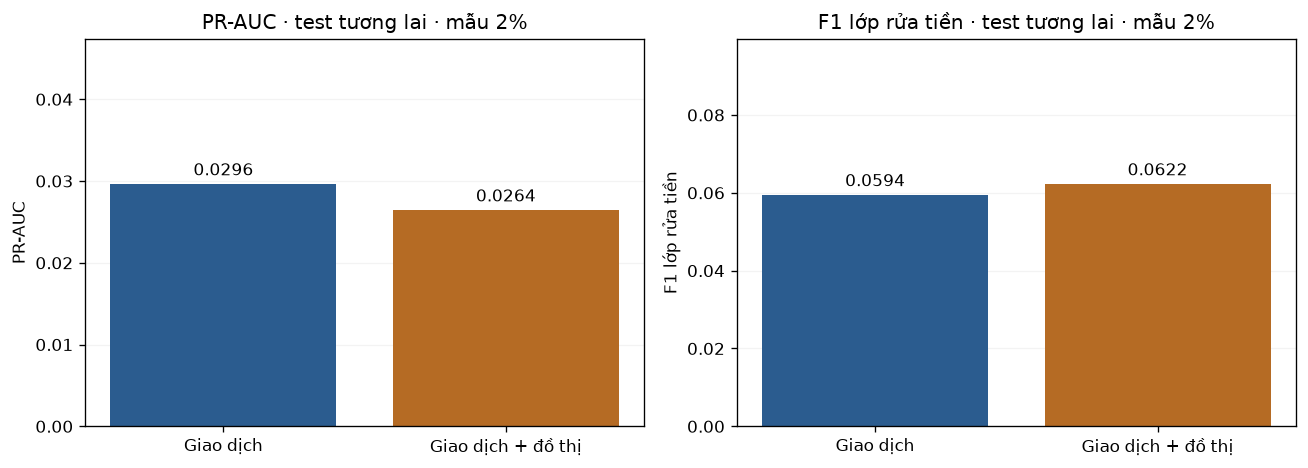

In [14]:
import matplotlib.pyplot as plt
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'figure.dpi':120})
fig,axes=plt.subplots(1,2,figsize=(11,4))
labels=['Giao dịch','Giao dịch + đồ thị']
for ax,index,title in [(axes[0],5,'PR-AUC'),(axes[1],8,'F1 lớp rửa tiền')]:
    bars=ax.bar(labels,[r[index] for r in results],color=['#2b5c8f','#b56b24'])
    upper = min(1.0, max(r[index] for r in results) * 1.6)
    ax.set(ylim=(0,upper),ylabel=title,title=f'{title} · test tương lai · mẫu {AML_FRACTION:.0%}')
    ax.bar_label(bars,fmt='%.4f',padding=3)
    ax.grid(axis='y',alpha=0.15);ax.set_axisbelow(True)
plt.tight_layout();plt.show()

### Nhận xét kết quả
So cột `accuracy` và `accuracy_at_0_5` để trả lời độ chính xác theo ngưỡng validation và ngưỡng mặc định.
Chênh lệch dương của PR-AUC/F1/recall cho biết đồ thị giúp nhận ra lớp rửa tiền trên lần chạy hiện tại; chênh lệch âm phải được báo cáo trung thực.
Degree biểu thị cường độ kết nối, số đối tác biểu thị mức phân tán/gom tiền, PageRank biểu thị vị trí mạng. Những thuộc tính này có thể bổ sung cho số tiền và phương thức giao dịch.
Snapshot cố định sẽ cũ dần và tài khoản mới thiếu đặc trưng; lấy mẫu cạnh càng làm yếu tín hiệu mạng.
Không được suy ra mô hình tốt chỉ vì accuracy gần 100% khi nhãn dương rất hiếm.
Lần chia theo thời gian này kiểm tra dự đoán tương lai trong cùng hệ thống; không phải đánh giá khả năng tổng quát sang một ngân hàng hay mạng hoàn toàn mới.

In [15]:
spark.stop()